CLUSTERING

It is basically a type of unsupervised learning method. An unsupervised learning method is a method in which we draw references from datasets consisting of input data without labeled responses. Generally, it is used as a process to find meaningful structure, explanatory underlying processes, generative features, and groupings inherent in a set of examples. 

Clustering is the task of dividing the population or data points into a number of groups such that data points in the same groups are more similar to other data points in the same group and dissimilar to the data points in other groups. It is basically a collection of objects on the basis of similarity and dissimilarity between them. 

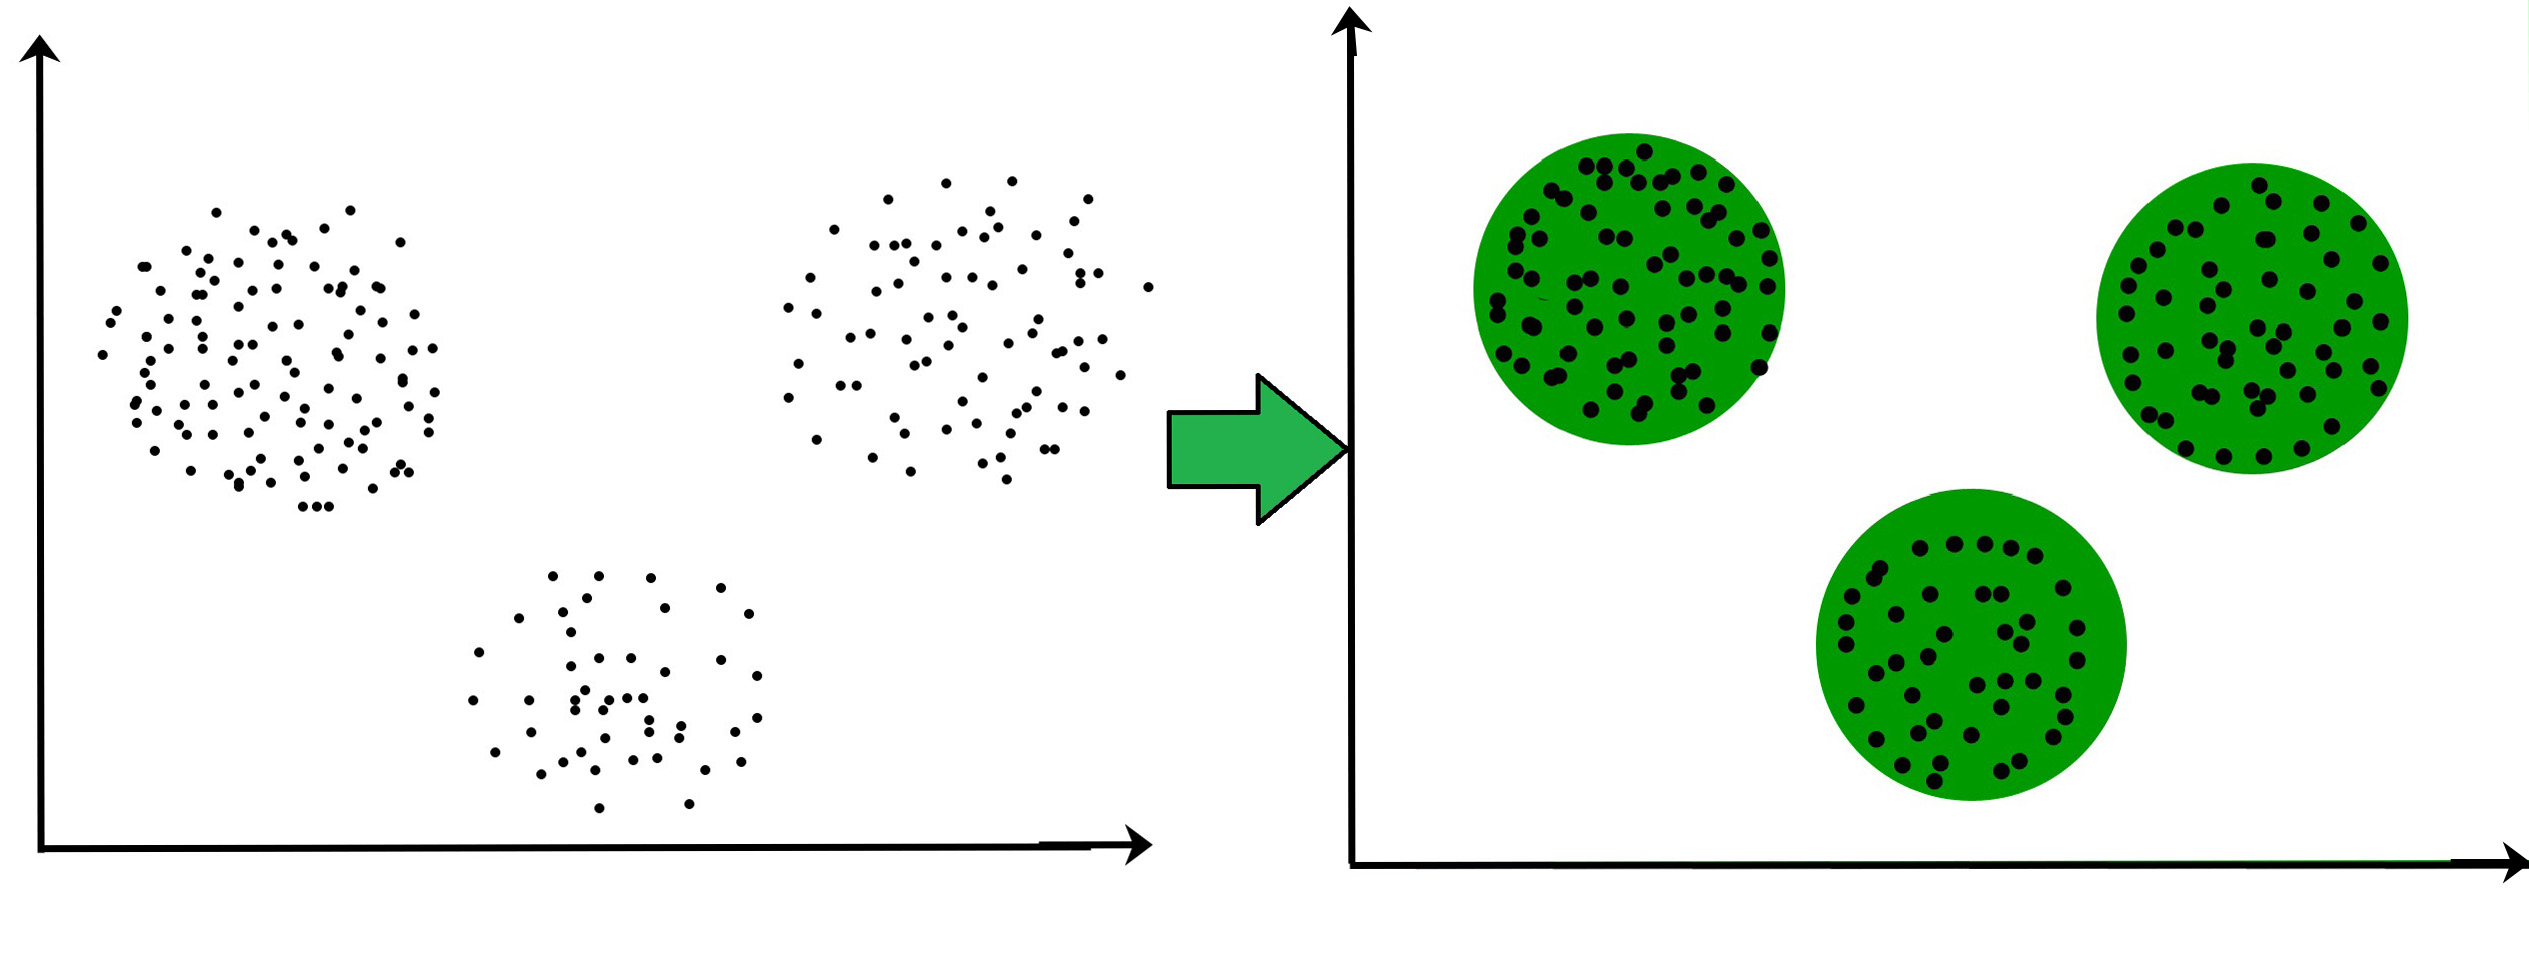
Elbow Method

The Elbow method is one of the most popular ways to find the optimal number of clusters. This method uses the concept of WCSS value. WCSS stands for Within Cluster Sum of Squares, which defines the total variations within a cluster. 



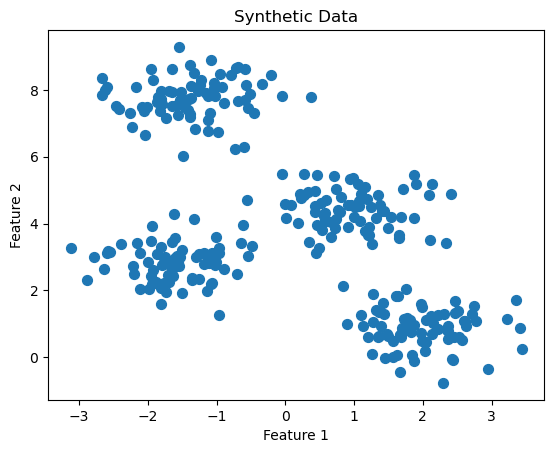

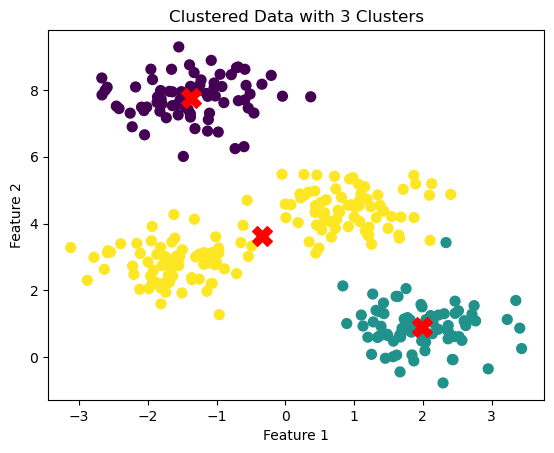

In [3]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# Generate a synthetic dataset
X, _ = make_blobs(n_samples=300, centers=4, random_state=0, cluster_std=0.60)

# Visualize the dataset
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Data")
plt.show()

# Initialize K-Means with a random number of clusters
num_clusters = np.random.randint(2, 6)  # Randomly select 2 to 5 clusters
kmeans = KMeans(n_clusters=num_clusters, init='random', random_state=0)

# Fit the model to the data
kmeans.fit(X)

# Get cluster labels for each data point
labels = kmeans.labels_

# Get cluster centers
centers = kmeans.cluster_centers_

# Visualize the clustered data
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, marker='X')
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title(f"Clustered Data with {num_clusters} Clusters")
plt.show()


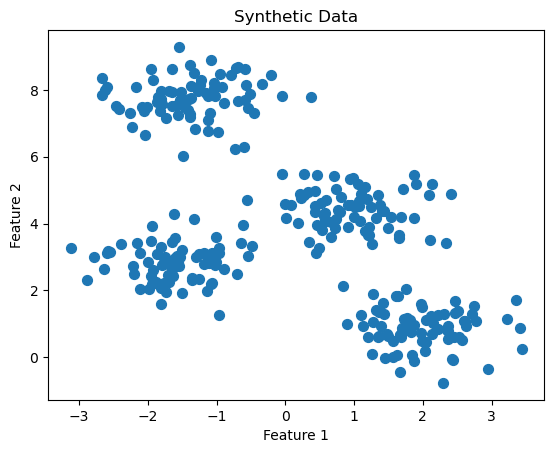

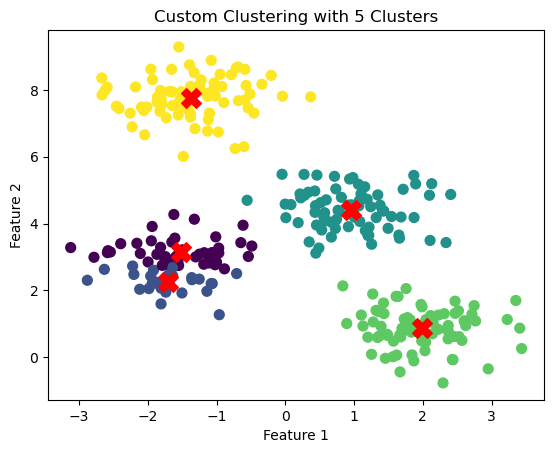

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Generate a synthetic dataset
X, _ = make_blobs(n_samples=300, centers=4, random_state=0, cluster_std=0.60)

# Visualize the dataset
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Data")
plt.show()

# Number of clusters (randomly initialized)
num_clusters = np.random.randint(2, 6)

# Randomly initialize cluster centroids
initial_centers = X[np.random.choice(X.shape[0], num_clusters, replace=False)]

# Maximum number of iterations
max_iterations = 50

# Tolerance to determine convergence
tolerance = 1e-4

# Initialize cluster centroids
centroids = initial_centers

# Assign points to clusters
def assign_clusters(X, centroids):
    distances = np.sqrt(((X - centroids[:, np.newaxis]) ** 2).sum(axis=2))
    return np.argmin(distances, axis=0)

# Update cluster centroids
def update_centroids(X, labels, num_clusters):
    new_centroids = np.zeros((num_clusters, X.shape[1]))
    for cluster_idx in range(num_clusters):
        cluster_points = X[labels == cluster_idx]
        if len(cluster_points) > 0:
            new_centroids[cluster_idx] = cluster_points.mean(axis=0)
    return new_centroids

# Main clustering loop
for i in range(max_iterations):
    # Assign points to clusters
    labels = assign_clusters(X, centroids)
    
    # Update cluster centroids
    new_centroids = update_centroids(X, labels, num_clusters)
    
    # Check for convergence
    if np.all(np.abs(new_centroids - centroids) < tolerance):
        break
    
    centroids = new_centroids

# Visualize the clustered data
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='X')
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title(f"Custom Clustering with {num_clusters} Clusters")
plt.show()


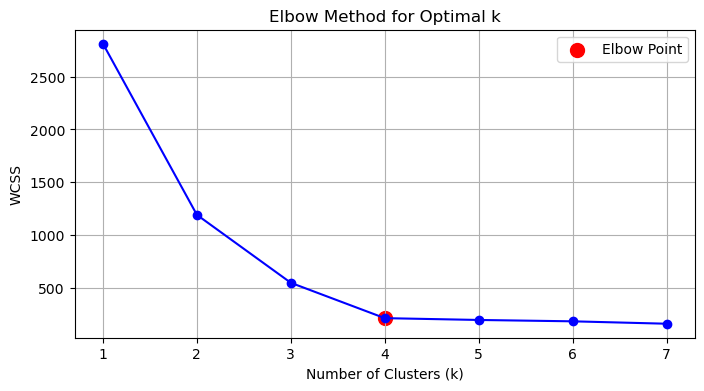

The optimal k value is: 4


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# Generate a synthetic dataset
X, _ = make_blobs(n_samples=300, centers=4, random_state=0, cluster_std=0.60)

# Number of clusters (randomly initialized)
max_k =7  # You can adjust the maximum number of clusters to consider
wcss = []   # Within-cluster sum of squares

# Maximum number of iterations
max_iterations = 50

# Tolerance to determine convergence
tolerance = 1e-4

# Assign points to clusters
def assign_clusters(X, centroids):
    distances = np.sqrt(((X - centroids[:, np.newaxis]) ** 2).sum(axis=2))
    return np.argmin(distances, axis=0)

# Update cluster centroids
def update_centroids(X, labels, num_clusters):
    new_centroids = np.zeros((num_clusters, X.shape[1]))
    for cluster_idx in range(num_clusters):
        cluster_points = X[labels == cluster_idx]
        if len(cluster_points) > 0:
            new_centroids[cluster_idx] = cluster_points.mean(axis=0)
    return new_centroids

for num_clusters in range(1, max_k + 1):
    # Randomly initialize cluster centroids
    initial_centers = X[np.random.choice(X.shape[0], num_clusters, replace=False)]
    centroids = initial_centers

    for i in range(max_iterations):
        # Assign points to clusters
        labels = assign_clusters(X, centroids)

        # Update cluster centroids
        new_centroids = update_centroids(X, labels, num_clusters)

        # Check for convergence
        if np.all(np.abs(new_centroids - centroids) < tolerance):
            break

        centroids = new_centroids

    # Calculate the within-cluster sum of squares (WCSS)
    wcss.append(np.sum((X - centroids[labels]) ** 2))

# Calculate the rate of change in WCSS
rate_of_change = np.diff(wcss)

# Find the "elbow point" where the rate of change slows down
elbow_point = None
for i in range(1, len(rate_of_change)):
    if (rate_of_change[i] - rate_of_change[i - 1]) < 25:
        elbow_point = i  # Add 1 to account for the difference calculation
        break

# Plot the WCSS values for different k values
plt.figure(figsize=(8, 4))
plt.plot(range(1, max_k + 1), wcss, marker='o', linestyle='-', color='b')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.title('Elbow Method for Optimal k')
plt.grid(True)

# Highlight the elbow point on the plot
plt.scatter(elbow_point, wcss[elbow_point - 1], c='red', s=100, label='Elbow Point', marker='o')
plt.legend()

plt.show()

# Find the optimal k value (elbow point)
optimal_k = elbow_point
print(f"The optimal k value is: {optimal_k}")

In [20]:
rate_of_change

array([-1372.2762001 ,  -892.97024474,  -334.88515425,   -23.17613655,
         -18.00238036,   -11.94631625,    15.83642628,   -33.68936652,
         -13.67497208])